# Calibration combinations

Main text

In [1]:
from pathlib import Path
import sys
from IPython.display import display, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/training_compat.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import classification_report as report, training_compat_report, compatibility_report
config=report.read(ROOT,'compatibility')
reference=report.paper(ROOT,'main_compatibility')
runs,mean,sd=compatibility_report.calculate(ROOT)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

Test set · 3 seeds per condition · mean ± sample SD.

In [2]:
report.show(report.table_frame(mean, sd, reference))

## Calibration

Diamonds: mean; bars: sample SD; circles: individual seeds.

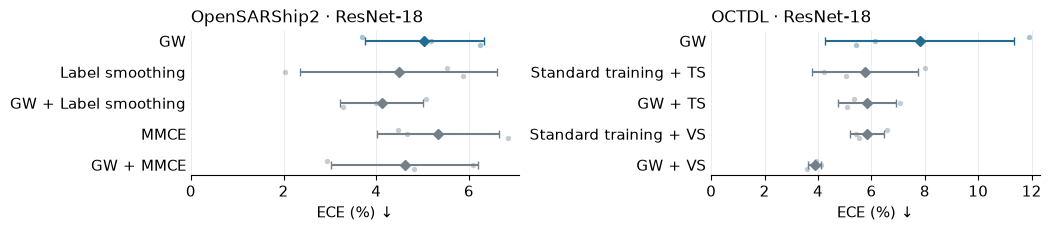

In [3]:
figure = report.plot(runs, mean, sd, ROOT / 'assets/figures/compatibility_ece.png')
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## Coverage

15 training-calibration checkpoints · 3 seeds per condition.

In [4]:
report.show(training_compat_report.coverage(ROOT))

,Checkpoint inference,Saved evaluations
Method,,
GW,3/3,0/3
Label smoothing,3/3,0/3
GW + Label smoothing,3/3,0/3
MMCE,3/3,0/3
GW + MMCE,3/3,0/3


## Settings

In [5]:
display(HTML('<details><summary>Settings</summary><div style="overflow:auto;max-height:420px">'+compact_settings(training_compat_report.settings(ROOT)).to_html(border=0,na_rep='—')+'<h4>Post-hoc models</h4>'+compact_settings(report.settings(report.read(ROOT,'posthoc_compat'))).to_html(border=0,na_rep='—')+'</div></details>'))

,Method,Input size,Supervised epochs,Warm-up epochs,Batch size,Learning rate,Weight decay,Label smoothing,MMCE strength,L,p,ρ,Selection
0,GW,128,50,5,128,0.001,0.0001,0.0,0.0,4.0,0.25,0.25,Validation NLL
1,Label smoothing,128,50,0,128,0.001,0.0001,0.1,0.0,—,—,—,Validation NLL
2,GW + Label smoothing,128,50,5,128,0.001,0.0001,0.1,0.0,4.0,0.25,0.25,Validation NLL
3,MMCE,128,50,0,128,0.001,0.0001,0.0,0.1,—,—,—,Validation NLL
4,GW + MMCE,128,50,5,128,0.001,0.0001,0.0,0.1,4.0,0.25,0.25,Validation NLL
,Dataset,Model,Method,Images,Input size,Supervised epochs,Warm-up epochs,Batch size,Learning rate,Weight decay,L,p,ρ
0,OCTDL,ResNet-18,GW,292,224,50,5,64,0.001,0.0001,1.0,0.50,1.0
1,OCTDL,ResNet-18,GW,292,224,50,5,64,0.001,0.0001,1.0,0.25,0.5
2,OCTDL,ResNet-18,GW,292,224,50,5,64,0.001,0.0001,1.0,0.25,1.0
3,OCTDL,ResNet-18,Standard training + TS,292,224,50,0,64,0.001,0.0001,—,—,—


## Training-time calibration

In [6]:
from pathlib import Path
import sys
from IPython.display import display, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/training_compat.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import classification_report as report, training_compat_report, compatibility_report
config=report.read(ROOT,'training_compat')
reference=report.paper(ROOT,'s6_training')
runs,mean,sd=training_compat_report.calculate(ROOT)

In [7]:
from gw.publication_ui import folded_table
folded_table('All metrics', report.table_frame(mean, sd, reference))
folded_comparison(report.comparison(mean, sd, reference))

## Inference

Set `RUN_INFERENCE = True` to evaluate the checkpoints.

In [8]:
from gw import training_compat_inference
RUN_INFERENCE=False
if RUN_INFERENCE:
    directory=training_compat_inference.run(ROOT,config,device='auto',available_only=True)
    runs,mean,sd=training_compat_report.calculate(ROOT,directory)
    report.show(report.table_frame(mean,sd,reference))
    report.show(training_compat_report.coverage(ROOT,directory))

## Training

Set `RUN_TRAINING = True` to train one configured seed and condition. Selection uses validation NLL.

In [9]:
from gw import classification_training
TRAIN_RUN='003'
RUN_TRAINING=False
if RUN_TRAINING:
    selected=next(r for r in config['runs'] if r['id']==TRAIN_RUN)
    print(classification_training.train(ROOT,'training_compat',selected,device='auto'))

## Post-hoc calibration

FP32 inference · validation-only fitting.

In [10]:
from pathlib import Path
import sys
from IPython.display import display, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/posthoc_compat.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import classification_report as report
from gw import posthoc
config = report.read(ROOT,'posthoc_compat')
reference = report.paper(ROOT,'s6_posthoc')
directory = ROOT/'results/posthoc_compat/model_refit_fp32'
runs,mean,sd = posthoc.summarize(ROOT,directory)

In [11]:
from gw.publication_ui import folded_table
folded_table('All metrics', report.table_frame(mean, sd, reference))
folded_comparison(report.comparison(mean, sd, reference))

## Inference

Set `RUN_INFERENCE = True` to evaluate the checkpoints.

In [12]:
from gw import posthoc_inference
RUN_INFERENCE = False
if RUN_INFERENCE:
    directory=posthoc_inference.run(ROOT,device='auto')
    runs,mean,sd=posthoc.summarize(ROOT,directory)
    report.show(report.table_frame(mean,sd,reference))

## Refit

Set `RUN_REFIT = True` to refit TS and VS using the displayed model predictions.

In [13]:
RUN_REFIT = False
if RUN_REFIT:
    directory=posthoc_inference.refit(ROOT, directory)
    runs,mean,sd=posthoc.summarize(ROOT,directory)
    report.show(report.table_frame(mean,sd,reference))